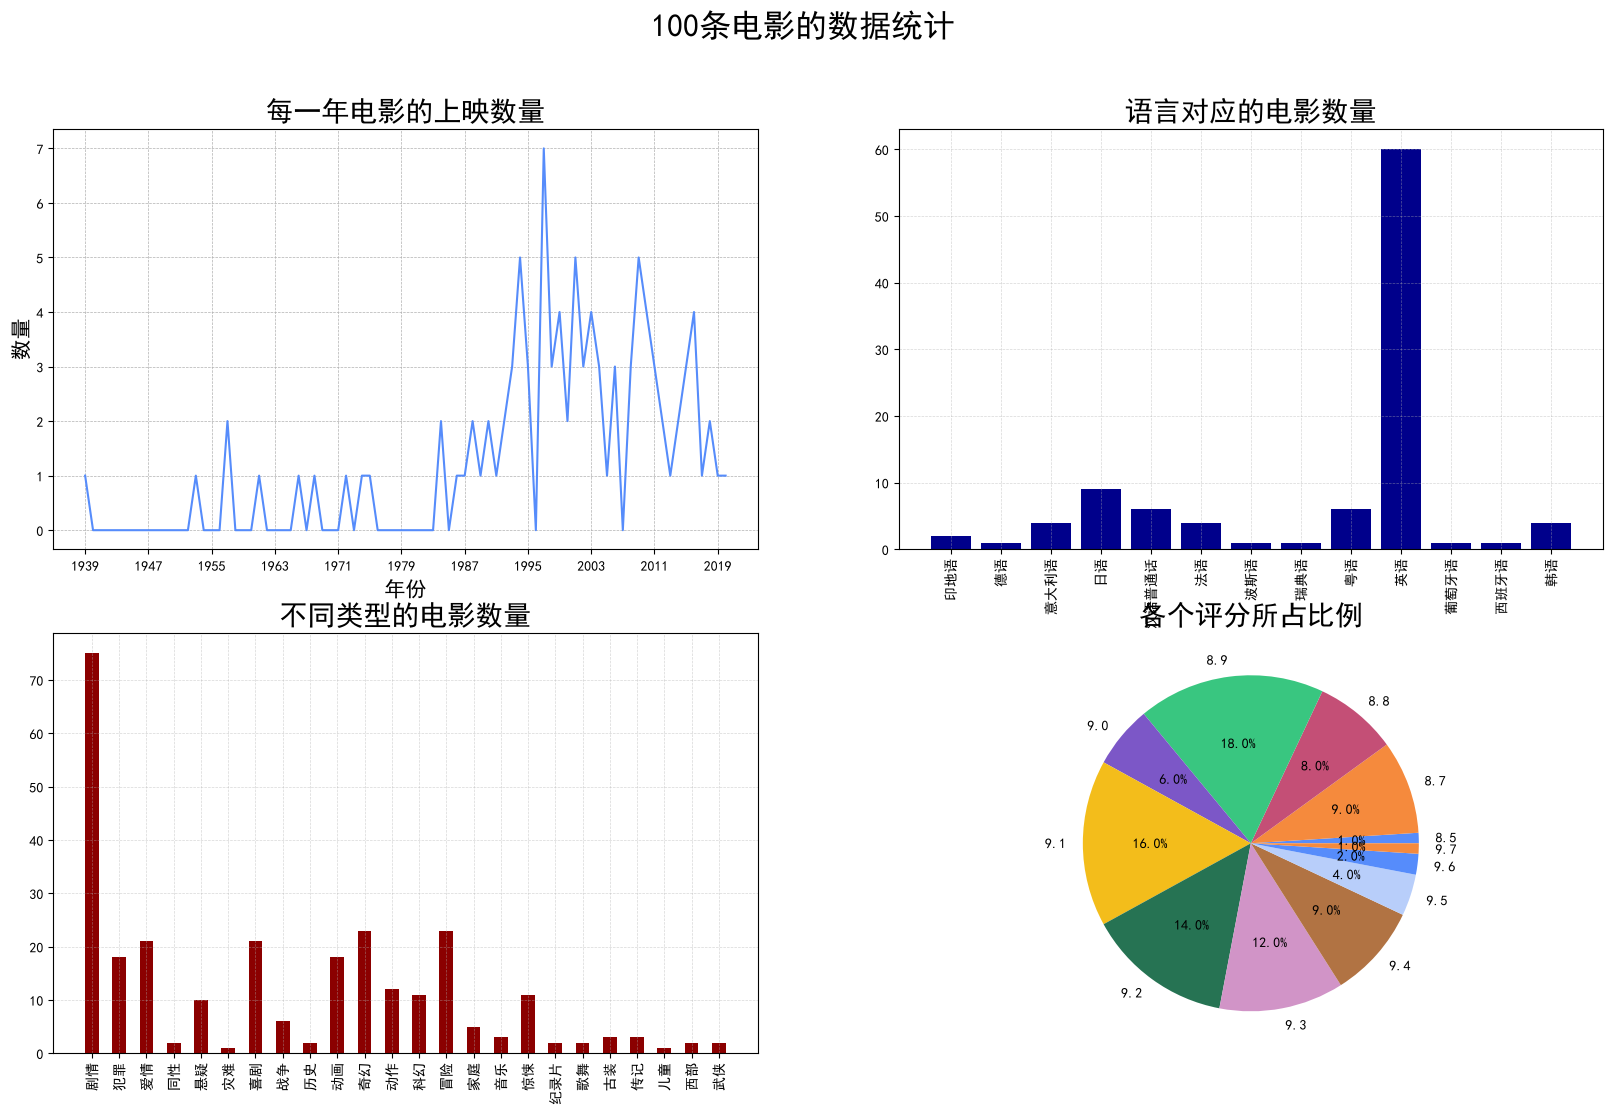

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.axes import Axes
plt.rcParams['font.sans-serif'] = ['SimHei']

figure,axes=plt.subplots(nrows=2, ncols=2, figsize=(20,12),dpi=100)
figure.suptitle("100条电影的数据统计",fontsize=23)
axes1:Axes=axes[0,0]
axes2:Axes=axes[0,1]
axes3:Axes=axes[1,0]
axes4:Axes=axes[1,1]

#加载数据
#int 64(不支持空值)
#Int64 (支持空值)
df=pd.read_csv("csv_data/电影数据_100条.csv",usecols=["电影名","年份","上映时间","类型","时长","评分","语言","导演","作者"])#如果想将小数转换为整形，在后面添加参数 dtype={'年份'：'Int64'}

#需求一 统计每一年上映电影的数量 用折线图表示
year=df.groupby("年份")["年份"].count()
min_year=year.index.min()
max_year=year.index.max()
x=[i for i in range(min_year,max_year+1)]
y=[year.get(i,0) for i in x]
axes1.plot(x,y)
axes1.set_title("每一年电影的上映数量",fontsize=20)
axes1.set_xlabel("年份",fontsize=15)
axes1.set_xticks(x[::8])
axes1.set_ylabel("数量",fontsize=15)
axes1.grid(linestyle="--",alpha=1)

#统计对比不同语言电影的数量
lan=df.groupby("语言")["语言"].count()
x=[i for i in lan.index]
y=[lan.get(i,0) for i in x]
axes2.bar(x,y,color="darkblue")
axes2.set_title("语言对应的电影数量",fontsize=20)
axes2.grid(linestyle="--",alpha=0.5)
axes2.tick_params(axis="x",rotation=90)
#旋转x轴

#统计对比不同类型电影数量
type_count={}
for types in df['类型'].str.split(','): # [剧情,犯罪]
    for type in types: # 剧情
        if type in type_count:
            type_count[type] += 1
        else:
            type_count[type] = 1
x=[i for i in type_count.keys()]
y=[i for i in type_count.values()]
axes3.bar(x,y,color="darkred",width=0.5)
axes3.set_title("不同类型的电影数量",fontsize=20)
axes3.grid(linestyle="--",alpha=0.5)
axes3.tick_params(axis="x",rotation=90)

#统计对比各个电影评分的比例
score_table=df.groupby("评分")["评分"].count()
x=[i for i in score_table.index]
y=[score_table.get(i,0) for i in x]
axes4.pie(y,labels=x,autopct="%1.1f%%")
axes4.set_title("各个评分所占比例",fontsize=20)
plt.show()